<a href="https://colab.research.google.com/github/jayhdajoiner/Jayhda_INFO4670_Fall2026/blob/main/Copy_of_Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

First five rows:
    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   User ID    400 non-null    int64 
 1   Gender     400 non-null    object
 2   Age        400 non-null    int64 
 3   Salary     400 non-null    int64 
 4   Purchased  400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None

Model Accuracy: 83.75 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        

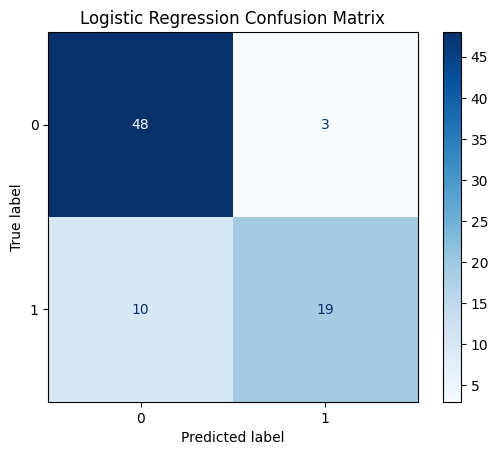

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Load the dataset
df = pd.read_csv('/content/car_purchase_data.csv')

# Preview the dataset
print("First five rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

# Separate independent and dependent variables
X = df[['Age', 'Salary']]
y = df['Purchased']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the logistic regression model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Predict the test set results
y_pred = model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap='Blues'
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()


### Step 2: Split features and target

In [13]:

# Separate features and target variable
X = df[['Age', 'Salary']]
y = df['Purchased']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Age  Salary
0   19   19000
1   35   20000
2   26   43000
3   27   57000
4   19   76000

Target:
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


### Step 3: Train/Test Split

In [14]:

from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 320
Testing samples: 80


### Step 4: Feature Scaling

In [15]:

from sklearn.preprocessing import StandardScaler

# Standardize Age and Salary
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully!")
print("First five scaled rows:")
print(X_train_scaled[:5])


Training data scaled successfully!
First five scaled rows:
[[-1.23446186 -0.367992  ]
 [-0.57764605 -1.05831408]
 [ 0.07916976  0.26480323]
 [ 1.95578636 -1.3747117 ]
 [ 0.36066225 -0.31046516]]


### Step 5: Train Logistic Regression Model

In [16]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Add nonlinear relationships between Age and Salary
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Tune polynomial logistic regression with cross-validation
parameters = {
    'C': [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    parameters,
    cv=cv,
    scoring='accuracy'
)

grid.fit(X_train_poly, y_train)

model = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print("Cross-validation accuracy:", round(grid.best_score_ * 100, 2), "%")


Best parameters: {'C': 1}
Cross-validation accuracy: 90.0 %


### Step 6: Predict and Evaluate

Model Accuracy: 91.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        51
           1       0.87      0.90      0.88        29

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.91        80
weighted avg       0.91      0.91      0.91        80



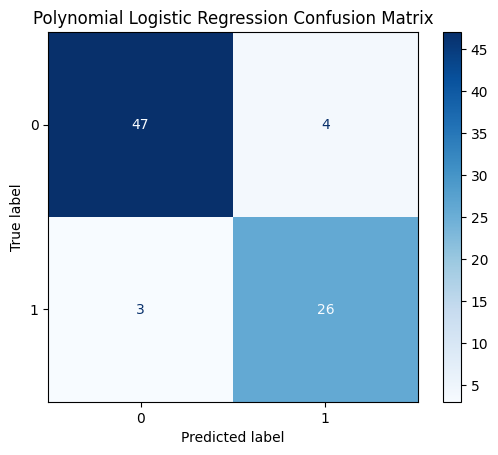

In [17]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_poly)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap='Blues'
)
plt.title("Polynomial Logistic Regression Confusion Matrix")
plt.show()


### Step 7: Visualization of Decision Regions

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


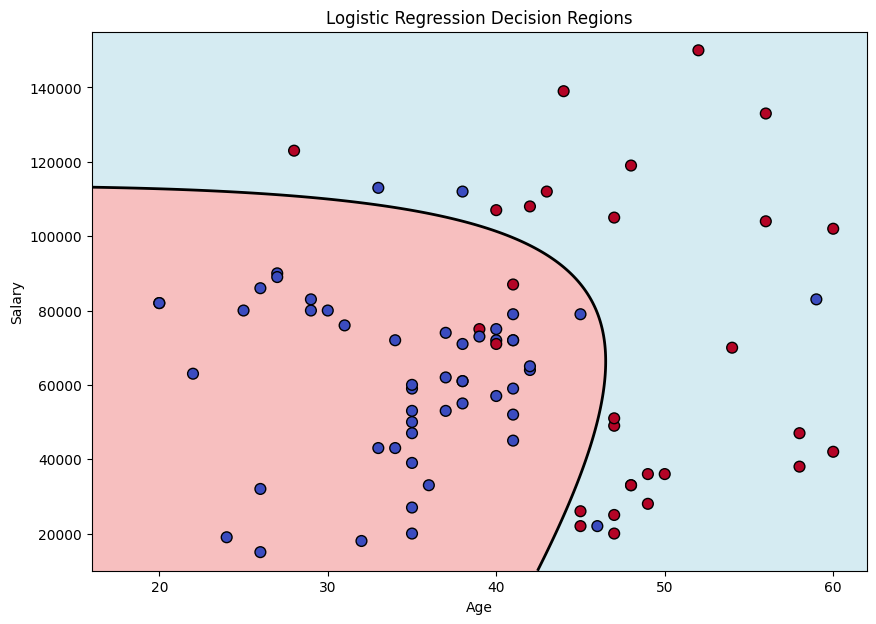

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Create a grid using Age and Salary
age_min, age_max = X['Age'].min() - 2, X['Age'].max() + 2
salary_min = X['Salary'].min() - 5000
salary_max = X['Salary'].max() + 5000

xx, yy = np.meshgrid(
    np.linspace(age_min, age_max, 300),
    np.linspace(salary_min, salary_max, 300)
)

# Prepare the grid for the trained model
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid_points)
grid_poly = poly.transform(grid_scaled)

# Predict purchasing probabilities
Z = model.predict_proba(grid_poly)[:, 1]
Z = Z.reshape(xx.shape)

# Plot the decision regions
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    levels=[0, 0.5, 1],
    colors=['lightcoral', 'lightblue'],
    alpha=0.5
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors='black',
    linewidths=2
)

# Plot actual customer data
plt.scatter(
    X_test['Age'],
    X_test['Salary'],
    c=y_test,
    cmap='coolwarm',
    edgecolors='black',
    s=60
)

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Logistic Regression Decision Regions')
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. Logistic regression uses probabilities to make predictions. If the probability is 0.5 or higher, it predicts the customer will buy a car. If it's below 0.5, it predicts they won't.

2. Based on the model that was made, older customers and those with higher salaries are more likely to buy a car because age and income can influence buying decisions.

3. Low accuracy could come from not having enough data or missing important information, but just because someone makes more money doesn't automatically mean they'll buy a car.


4. Adding information like credit scores, employment, or previous car purchases could help. Using different model settings and polynomial features could also improve accuracy, like we saw when our model reached 91.25%.